Optimal Path from 0 to 5: [0, np.int64(2), np.int64(4), np.int64(5)]
Estimated Total Travel Time (with congestion): 30.00


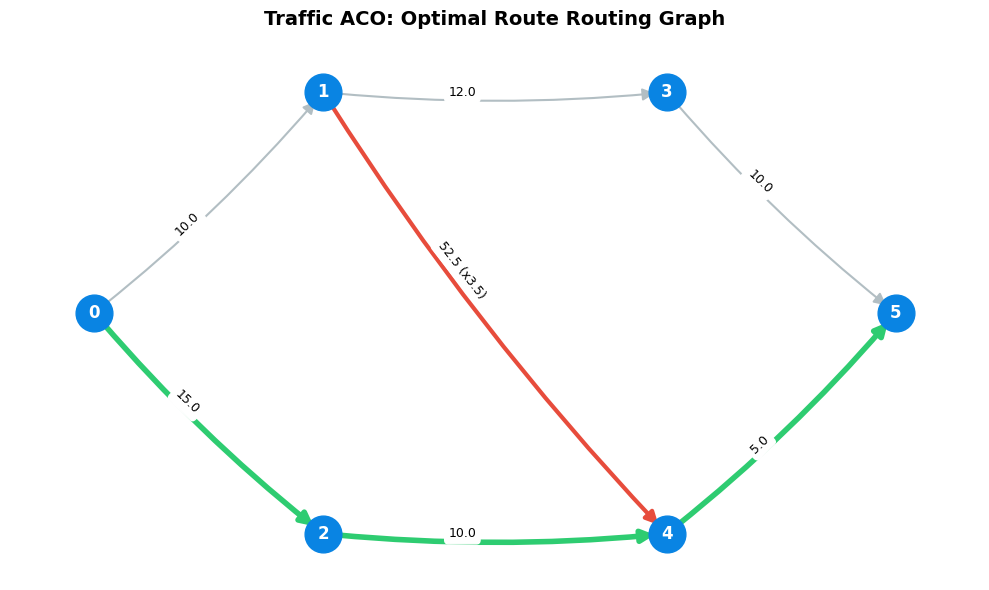

In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt
import networkx as nx

class TrafficACO:
    def __init__(self, n_nodes, n_ants, n_iterations, alpha=1.0, beta=2.0, evaporation_rate=0.5, Q=100):
        self.n_nodes = n_nodes
        self.n_ants = n_ants
        self.n_iterations = n_iterations
        self.alpha = alpha
        self.beta = beta
        self.evaporation_rate = evaporation_rate
        self.Q = Q

        self.base_cost = np.ones((n_nodes, n_nodes)) * np.inf
        np.fill_diagonal(self.base_cost, 0)

        self.congestion = np.ones((n_nodes, n_nodes))

        self.pheromone = np.ones((n_nodes, n_nodes)) * 0.1

    def add_road(self, u, v, travel_time):
        """Add a directed road from node u to node v with a base travel time."""
        self.base_cost[u][v] = travel_time

    def update_congestion(self, u, v, congestion_multiplier):
        """Update traffic congestion multiplier on edge (u, v)."""
        self.congestion[u][v] = congestion_multiplier

    def get_effective_cost(self, u, v):
        """Effective cost = base travel time * congestion penalty."""
        return self.base_cost[u][v] * self.congestion[u][v]

    def run(self, start_node, end_node):
        best_path = None
        best_cost = float('inf')

        for iteration in range(self.n_iterations):
            all_paths = []
            all_costs = []

            for ant in range(self.n_ants):
                path = [start_node]
                current_node = start_node
                visited = set([start_node])
                cost = 0
                dead_end = False

                while current_node != end_node:
                    neighbors = []
                    probabilities = []

                    for next_node in range(self.n_nodes):
                        if next_node not in visited and self.base_cost[current_node][next_node] != np.inf:
                            tau = self.pheromone[current_node][next_node] ** self.alpha
                            eff_cost = self.get_effective_cost(current_node, next_node)
                            eta = (1.0 / max(eff_cost, 0.0001)) ** self.beta
                            neighbors.append(next_node)
                            probabilities.append(tau * eta)

                    if not neighbors:
                        dead_end = True
                        break

                    probabilities = np.array(probabilities)
                    if probabilities.sum() == 0:
                        next_node = random.choice(neighbors)
                    else:
                        probabilities /= probabilities.sum()
                        next_node = np.random.choice(neighbors, p=probabilities)

                    cost += self.get_effective_cost(current_node, next_node)
                    path.append(next_node)
                    visited.add(next_node)
                    current_node = next_node

                if not dead_end and current_node == end_node:
                    all_paths.append(path)
                    all_costs.append(cost)
                    if cost < best_cost:
                        best_cost = cost
                        best_path = path

            self.pheromone *= (1.0 - self.evaporation_rate)

            for path, cost in zip(all_paths, all_costs):
                for i in range(len(path) - 1):
                    u, v = path[i], path[i+1]
                    self.pheromone[u][v] += self.Q / cost

        return best_path, best_cost


def plot_graph(roads, aco, optimal_path):
    """Generates and displays a visual plot of the traffic network."""
    G = nx.DiGraph()

    for u, v, t in roads:
        eff_cost = aco.get_effective_cost(u, v)
        G.add_edge(u, v, weight=eff_cost)

    pos = {
        0: (0, 2),
        1: (2, 4),
        2: (2, 0),
        3: (5, 4),
        4: (5, 0),
        5: (7, 2)
    }

    optimal_edges = list(zip(optimal_path[:-1], optimal_path[1:])) if optimal_path else []

    edge_colors = []
    edge_widths = []
    for u, v in G.edges():
        if (u, v) in optimal_edges:
            edge_colors.append('#2ecc71')
            edge_widths.append(4.0)
        elif aco.congestion[u][v] > 1.0:
            edge_colors.append('#e74c3c')
            edge_widths.append(3.0)
        else:
            edge_colors.append('#b2bec3')
            edge_widths.append(1.5)

    plt.figure(figsize=(10, 6))
    plt.title("Traffic ACO: Optimal Route Routing Graph", fontsize=14, fontweight='bold', pad=15)


    nx.draw_networkx_nodes(G, pos, node_color='#0984e3', node_size=700)
    nx.draw_networkx_labels(G, pos, font_color='white', font_weight='bold')
    nx.draw_networkx_edges(G, pos, edge_color=edge_colors, width=edge_widths, arrowsize=18, connectionstyle='arc3,rad=0.05')


    edge_labels = {}
    for u, v in G.edges():
        congestion_txt = f" (x{aco.congestion[u][v]})" if aco.congestion[u][v] > 1.0 else ""
        edge_labels[(u, v)] = f"{G[u][v]['weight']:.1f}{congestion_txt}"

    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9, label_pos=0.4)

    plt.axis('off')
    plt.tight_layout()
    plt.show()



if __name__ == "__main__":
    n_nodes = 6
    aco = TrafficACO(n_nodes=n_nodes, n_ants=10, n_iterations=50)

    roads = [
        (0, 1, 10), (0, 2, 15),
        (1, 3, 12), (1, 4, 15),
        (2, 4, 10),
        (3, 5, 10),
        (4, 5, 5)
    ]
    for u, v, t in roads:
        aco.add_road(u, v, t)


    aco.update_congestion(1, 4, congestion_multiplier=3.5)

    start, target = 0, 5
    optimal_path, total_travel_time = aco.run(start_node=start, end_node=target)

    print(f"Optimal Path from {start} to {target}: {optimal_path}")
    print(f"Estimated Total Travel Time (with congestion): {total_travel_time:.2f}")


    plot_graph(roads, aco, optimal_path)
